# Infostop Stop Detection

Infostop is a stop detection algorithm implemented in `nomad` that combines a sequential scan with network clustering, following _Infostop: Scalable stop-location detection in multi-user mobility data_ (Aslak & Alessandretti). It first finds stationary events, then groups them into recurring locations, so that separate visits to the same place share a `location_cluster`.

* A stationary event is a sequence of consecutive pings that stay close to the running median of the event.
* Event medians that are close to each other are linked into a network, and the Infomap algorithm partitions that network into locations.

This algorithm has the following parameters:
* `r1`: Maximum distance between a ping and the median of its stationary event in meters.
* `r2`: Maximum distance between two event medians in the same location in meters.
* `dur_min`: Minimum duration for a stationary event in minutes.
* `dt_max`: Maximum time gap permitted between consecutive pings in a visit in minutes.

In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt

# Imports
import nomad.io.base as loader
import geopandas as gpd
from shapely.geometry import box
from nomad.stop_detection.viz import plot_stops_barcode, plot_time_barcode, plot_stops, plot_pings
from nomad.stop_detection.infostop import infostop
import nomad.data as data_folder
from pathlib import Path

# Load data
data_dir = Path(data_folder.__file__).parent
city = gpd.read_parquet(data_dir / 'garden-city-buildings-mercator.parquet')
outer_box = box(*city.total_bounds)

filepath_root = data_dir / "gc_data_long"
tc = {"user_id": "gc_identifier", "x": "dev_x", "y": "dev_y", "timestamp": "unix_ts"}

users = ['admiring_brattain']
traj = loader.sample_from_file(filepath_root, format='parquet', users=users, filters=('date','==', '2024-01-01'), traj_cols=tc)

# Infostop (stationary events clustered with Infomap)
stops = infostop(traj, r1=20, r2=30, dt_max=60, dur_min=5, complete_output=True, keep_col_names=True, traj_cols=tc)

Each circle is one visit: consecutive event pings at the same location, drawn at their medoid and sized by their diameter. Each colored band in the barcode is a visit's time span. Colors show the Infomap `location_cluster`, so separate visits to the same place share a color.

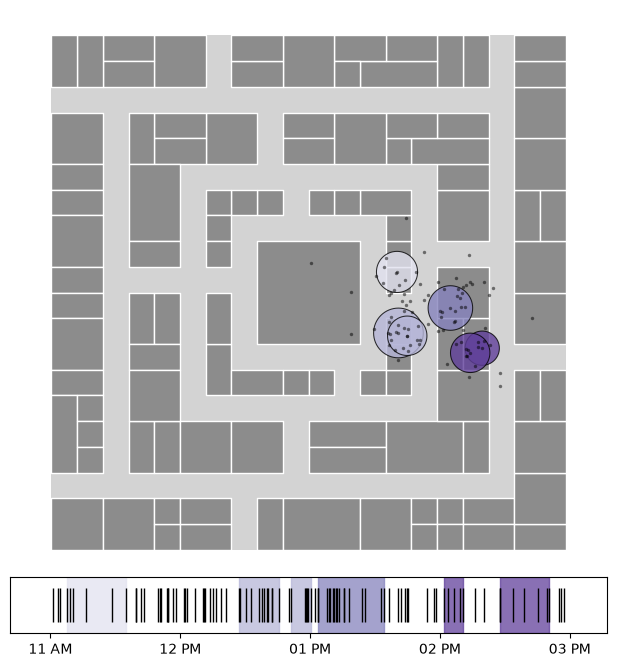

In [2]:
# Color by location so separate visits to the same place share a color
locations = stops.assign(cluster=stops['location_cluster'])

fig, (ax_map, ax_barcode) = plt.subplots(2, 1, figsize=(6,6.5),
                                         gridspec_kw={'height_ratios':[10,1]})

gpd.GeoDataFrame(geometry=[outer_box], crs='EPSG:3857').plot(ax=ax_map, color='#d3d3d3')
city.plot(ax=ax_map, edgecolor='white', linewidth=1, color='#8c8c8c')

plot_stops(locations, ax=ax_map, cmap='Purples', traj_cols=tc)
plot_pings(traj, ax=ax_map, s=6, color='black', alpha=0.5, traj_cols=tc)
ax_map.set_axis_off()

plot_time_barcode(traj['unix_ts'], ax=ax_barcode, set_xlim=True)
plot_stops_barcode(locations, ax=ax_barcode, cmap='Purples', set_xlim=False, timestamp='unix_ts')

plt.tight_layout(pad=0.1)
plt.show()